# Import libraries 

In [1]:
import pandas as pd  # pandas helps us work with tabular data
import numpy as np  # numpy helps us perform numerical calculations

import matplotlib.pyplot as plt  # matplotlib helps us create visualizations
import seaborn as sns  # seaborn helps us create statistical visualizations

from sklearn.preprocessing import LabelEncoder  # converts categories into numbers
from sklearn.preprocessing import StandardScaler  # standardizes numerical features

from sklearn.model_selection import train_test_split  # splits data into train and test sets

from sklearn.cluster import KMeans  # K-Means clustering algorithm
from sklearn.cluster import AgglomerativeClustering  # Hierarchical clustering algorithm

from sklearn.metrics import silhouette_score  # measures clustering quality

from scipy.cluster.hierarchy import dendrogram  # creates dendrogram
from scipy.cluster.hierarchy import linkage  # calculates hierarchical linkage

from sklearn.linear_model import LogisticRegression  # traditional classification model

from sklearn.metrics import (
    accuracy_score,  # calculates accuracy
    precision_score,  # calculates precision
    recall_score,  # calculates recall
    f1_score , # calculates F1-score
    confusion_matrix
)

import tensorflow as tf  # TensorFlow helps us build neural networks
from tensorflow.keras.models import Sequential  # creates sequential neural networks
from tensorflow.keras.layers import Dense, Dropout  # creates neural network layers
from tensorflow.keras.callbacks import EarlyStopping  # stops training when performance stops improving

# Load Dataset

In [2]:
df = pd.read_csv(
    "/Users/shyamalkar/Desktop/ML_project/05_ Food_Delivery_Time_Prediction/Food_Delivery_Time_Prediction (3).csv"
)  # load the food delivery dataset

df.head()  # display the first five rows

FileNotFoundError: [Errno 2] No such file or directory: '/Users/shyamalkar/Desktop/ML_project/05_ Food_Delivery_Time_Prediction/Food_Delivery_Time_Prediction (3).csv'

# Understand the dataset

In [ ]:
print("Dataset Shape:", df.shape)  # display rows and columns

print("\nColumn Names:")
print(df.columns)  # display all column names

print("\nData Types:")
print(df.dtypes)  # display data types

Dataset Shape: (200, 15)

Column Names:
Index(['Order_ID', 'Customer_Location', 'Restaurant_Location', 'Distance',
       'Weather_Conditions', 'Traffic_Conditions',
       'Delivery_Person_Experience', 'Order_Priority', 'Order_Time',
       'Vehicle_Type', 'Restaurant_Rating', 'Customer_Rating', 'Delivery_Time',
       'Order_Cost', 'Tip_Amount'],
      dtype='str')

Data Types:
Order_ID                          str
Customer_Location                 str
Restaurant_Location               str
Distance                      float64
Weather_Conditions                str
Traffic_Conditions                str
Delivery_Person_Experience      int64
Order_Priority                    str
Order_Time                        str
Vehicle_Type                      str
Restaurant_Rating             float64
Customer_Rating               float64
Delivery_Time                 float64
Order_Cost                    float64
Tip_Amount                    float64
dtype: object


In [ ]:
print(df.isnull().sum()) # count missing values in every column

Order_ID                      0
Customer_Location             0
Restaurant_Location           0
Distance                      0
Weather_Conditions            0
Traffic_Conditions            0
Delivery_Person_Experience    0
Order_Priority                0
Order_Time                    0
Vehicle_Type                  0
Restaurant_Rating             0
Customer_Rating               0
Delivery_Time                 0
Order_Cost                    0
Tip_Amount                    0
dtype: int64


# Feature engineering 

In [ ]:
import ast  # ast safely converts coordinate strings into Python tuples

df[
    ['Customer_Latitude', 'Customer_Longitude']
] = df['Customer_Location'].apply(
    lambda x: pd.Series(ast.literal_eval(x))
)  # extract customer latitude and longitude

df[
    ['Restaurant_Latitude', 'Restaurant_Longitude']
] = df['Restaurant_Location'].apply(
    lambda x: pd.Series(ast.literal_eval(x))
)  # extract restaurant latitude and longitude

# Haver sine function

In [ ]:
def haversine_distance(lat1, lon1, lat2, lon2):

    R = 6371  # Earth's radius in kilometers

    lat1 = np.radians(lat1)  # convert customer latitude to radians
    lon1 = np.radians(lon1)  # convert customer longitude to radians

    lat2 = np.radians(lat2)  # convert restaurant latitude to radians
    lon2 = np.radians(lon2)  # convert restaurant longitude to radians

    dlat = lat2 - lat1  # calculate latitude difference
    dlon = lon2 - lon1  # calculate longitude difference

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1)
        * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )  # calculate Haversine intermediate value

    c = 2 * np.arcsin(
        np.sqrt(a)
    )  # calculate angular distance

    return R * c  # return distance in kilometers

In [ ]:
df['Haversine_Distance'] = haversine_distance(
    df['Customer_Latitude'],
    df['Customer_Longitude'],
    df['Restaurant_Latitude'],
    df['Restaurant_Longitude']
)  # calculate geographical distance

In [ ]:
df[
    [
        'Distance',
        'Haversine_Distance'
    ]
].head()

,Distance,Haversine_Distance
0,1.57,775.651198
1,21.32,1042.385597
2,6.95,476.220706
3,13.79,389.912629
4,6.72,806.505886


# Encode Categorical Features 

In [ ]:
categorical_features = [
    'Weather_Conditions',
    'Traffic_Conditions',
    'Order_Priority',
    'Order_Time',
    'Vehicle_Type'
]  # list categorical features

In [ ]:
encoders = {}  # create a dictionary to store encoders

for column in categorical_features:

    encoder = LabelEncoder()  # create a LabelEncoder

    df[column + '_Encoded'] = encoder.fit_transform(
        df[column]
    )  # convert categories into numerical values

    encoders[column] = encoder  # store the encoder

In [ ]:
# We will create a binary Feature 
df['Rush_Hour'] = df['Order_Time'].isin(
    ['Morning', 'Evening']
).astype(int)  # identify morning and evening as rush-hour periods

In [ ]:
# Check 
df[
    ['Order_Time', 'Rush_Hour']
].head()

,Order_Time,Rush_Hour
0,Afternoon,0
1,Night,0
2,Night,0
3,Evening,1
4,Night,0


# Create Delivery status

In [ ]:
delivery_threshold = df['Delivery_Time'].median()  # calculate the median delivery time

In [ ]:
df['Delayed'] = (df['Delivery_Time'] > delivery_threshold).astype(int)  # classify deliveries as fast or delayed

In [ ]:
# Check 

print(
    df['Delayed'].value_counts()
)  # count fast and delayed deliveries

Delayed
0    100
1    100
Name: count, dtype: int64


# K - Means Clustering 
`Select Clustering Features `

In [ ]:
clustering_features = [
    'Haversine_Distance',
    'Delivery_Time',
    'Delivery_Person_Experience',
    'Restaurant_Rating',
    'Customer_Rating',
    'Order_Cost',
    'Tip_Amount',
    'Weather_Conditions_Encoded',
    'Traffic_Conditions_Encoded',
    'Order_Priority_Encoded',
    'Rush_Hour'
]  # select features for clustering

In [ ]:
X_cluster = df[
    clustering_features
]  # create clustering dataset

In [ ]:
# Scale them 
cluster_scaler = StandardScaler()  # create a scaler

X_cluster_scaled = cluster_scaler.fit_transform(
    X_cluster
)  # standardize clustering features

In [ ]:
# Elbow method 
inertia = []  # store K-Means inertia values

k_values = range(2, 11)  # test cluster numbers from 2 to 10

for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )  # create K-Means model

    kmeans.fit(
        X_cluster_scaled
    )  # train K-Means

    inertia.append(
        kmeans.inertia_
    )  # store inertia

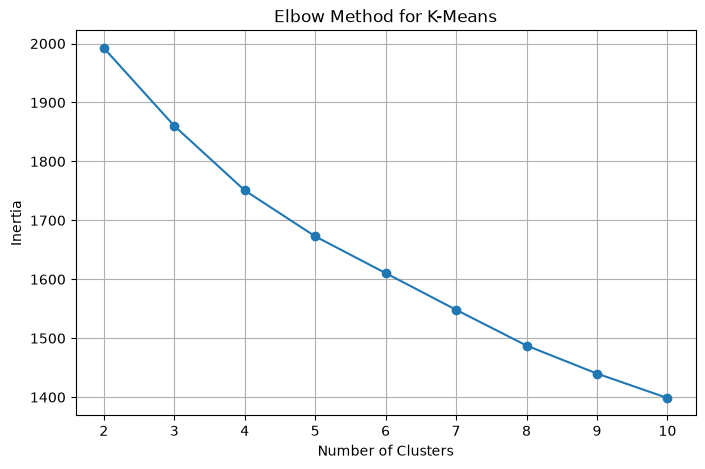

In [ ]:
# Plot 
plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    inertia,
    marker='o'
)  # plot the elbow curve

plt.title('Elbow Method for K-Means')
plt.xlabel('Number of Clusters')
plt.ylabel('Inertia')
plt.grid(True)
plt.show()

# Train K-Means

In [ ]:
kmeans = KMeans(
    n_clusters= 3,
    random_state=42,
    n_init=10
)  # create the final K-Means model

In [ ]:
df['KMeans_Cluster'] = kmeans.fit_predict(
    X_cluster_scaled
)  # assign every order to a cluster

In [ ]:
# Check 
df[
    'KMeans_Cluster'
].value_counts()

KMeans_Cluster
1    79
2    62
0    59
Name: count, dtype: int64

# Evaluate k-means

In [ ]:
silhouette_kmeans = silhouette_score(
    X_cluster_scaled,
    df['KMeans_Cluster']
)  # calculate silhouette score

print(
    "K-Means Silhouette Score:",
    round(silhouette_kmeans, 4)
)

K-Means Silhouette Score: 0.0828


# Visualize K-Means Clusters 

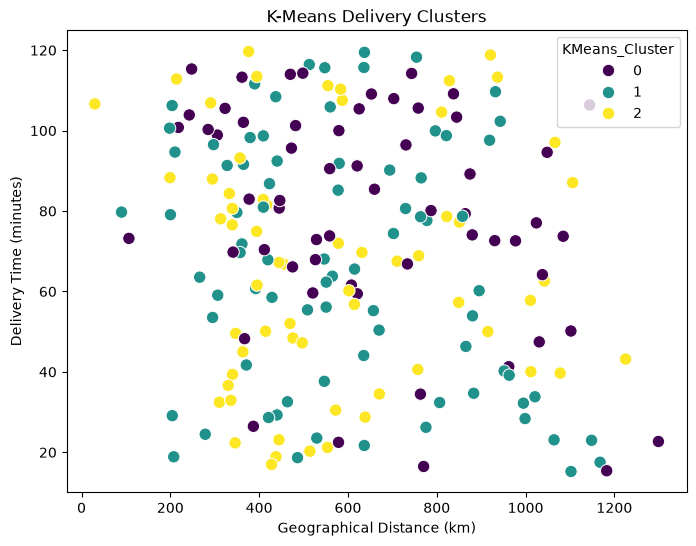

In [ ]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x='Haversine_Distance',
    y='Delivery_Time',
    hue='KMeans_Cluster',
    palette='viridis',
    s=80
)  # visualize delivery clusters

plt.title('K-Means Delivery Clusters')
plt.xlabel('Geographical Distance (km)')
plt.ylabel('Delivery Time (minutes)')
plt.show()

# Hierarchical Clustering 

In [ ]:
# Create Dendogram 
linkage_matrix = linkage(
    X_cluster_scaled,
    method='ward'
)  # calculate hierarchical clusters using Ward linkage

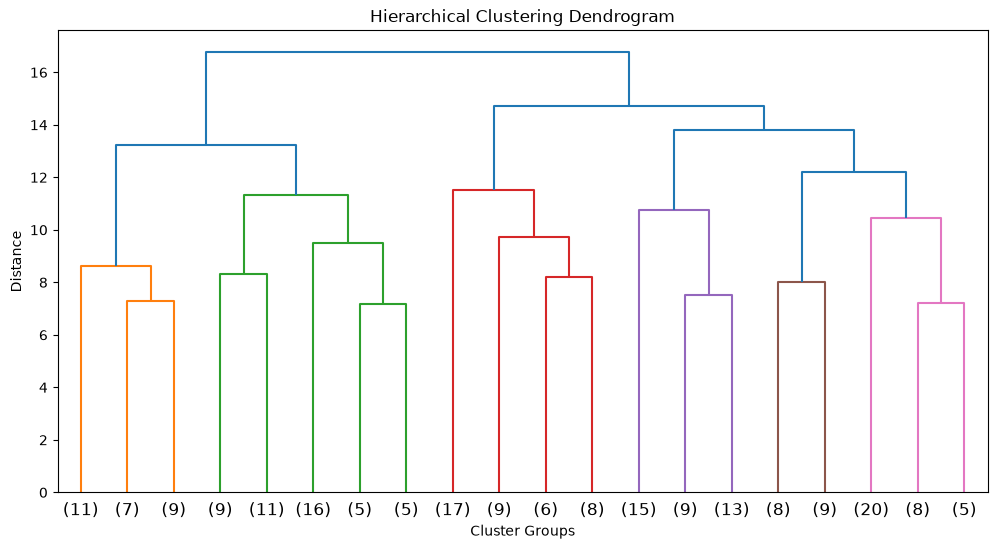

In [ ]:
plt.figure(figsize=(12, 6))

dendrogram(
    linkage_matrix,
    truncate_mode='lastp',
    p=20
)  # create the hierarchical clustering dendrogram

plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Cluster Groups')
plt.ylabel('Distance')
plt.show()

In [ ]:
hierarchical_model = AgglomerativeClustering(
    n_clusters=3,
    linkage='ward'
)  # create hierarchical clustering model

In [ ]:
df['Hierarchical_Cluster'] = hierarchical_model.fit_predict(
    X_cluster_scaled
)  # assign hierarchical cluster labels

# Hierarchical Clustering Evaluation 

In [ ]:
silhouette_hierarchical = silhouette_score(
    X_cluster_scaled,
    df['Hierarchical_Cluster']
)  # calculate hierarchical silhouette score

print(
    "Hierarchical Silhouette Score:",
    round(silhouette_hierarchical, 4)
)

Hierarchical Silhouette Score: 0.0532


# Visualize Hierarchical Clusters 

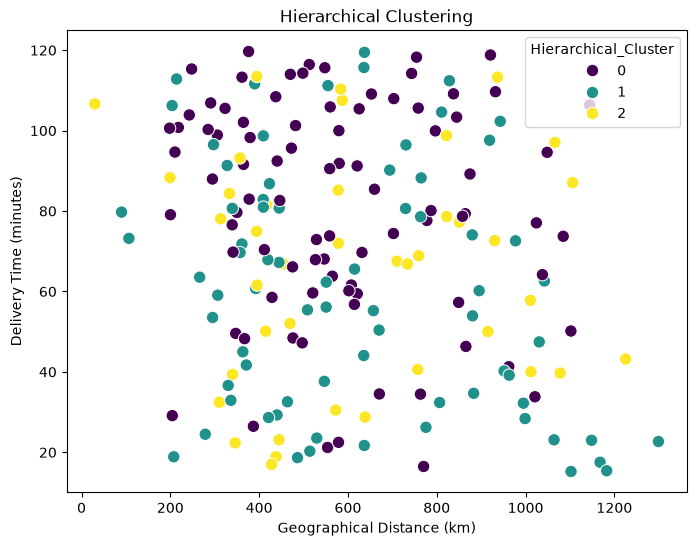

In [ ]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x='Haversine_Distance',
    y='Delivery_Time',
    hue='Hierarchical_Cluster',
    palette='viridis',
    s=80
)  # visualize hierarchical clusters

plt.title('Hierarchical Clustering')
plt.xlabel('Geographical Distance (km)')
plt.ylabel('Delivery Time (minutes)')
plt.show()

# Analyze K-Means Clusters 

In [ ]:
kmeans_analysis = df.groupby(
    'KMeans_Cluster'
)[
    [
        'Haversine_Distance',
        'Delivery_Time',
        'Order_Cost',
        'Tip_Amount',
        'Restaurant_Rating'
    ]
].mean().round(2)  # calculate average characteristics of each cluster

kmeans_analysis

,Haversine_Distance,Delivery_Time,Order_Cost,Tip_Amount,Restaurant_Rating
KMeans_Cluster,,,,,
0,650.62,79.33,1446.68,36.60,3.62
1,593.37,66.84,772.55,54.51,3.76
2,570.07,66.75,1014.72,46.09,3.82


# Neural Network 

In [ ]:
nn_features = [
    'Haversine_Distance',
    'Weather_Conditions_Encoded',
    'Traffic_Conditions_Encoded',
    'Delivery_Person_Experience',
    'Order_Priority_Encoded',
    'Rush_Hour',
    'Vehicle_Type_Encoded',
    'Restaurant_Rating',
    'Customer_Rating',
    'Order_Cost',
    'Tip_Amount'
]  # select features for neural network

In [ ]:
X = df[nn_features]  # create neural network input features

y = df['Delayed']  # create binary target

# Train Test split 

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)  # split data into training and testing sets

# Normalize Neural Network Features 

In [ ]:
nn_scaler = StandardScaler()  # create standard scaler

X_train_scaled = nn_scaler.fit_transform(
    X_train
)  # fit scaler only on training data

X_test_scaled = nn_scaler.transform(
    X_test
)  # transform test data using the training scaler

# Build neural network 

In [ ]:
model = Sequential([
    
    Dense(
        32,
        activation='relu',
        input_shape=(X_train_scaled.shape[1],)
    ),  # first hidden layer with 32 neurons

    Dense(
        16,
        activation='relu'
    ),  # second hidden layer with 16 neurons

    Dropout(
        0.2
    ),  # randomly deactivate 20% of neurons to reduce overfitting

    Dense(
        1,
        activation='sigmoid'
    )  # output layer for binary classification
])

/Users/shyamalkar/Desktop/ML_project/MLvenv/lib/python3.14/site-packages/keras/src/layers/core/dense.py:102: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


# Compile Neural Network 

In [ ]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)  # configure the neural network for binary classification

# Train Neural Network 


In [ ]:
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)  # stop training when validation performance stops improving

In [ ]:
history = model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=16,
    callbacks=[early_stopping],
    verbose=1
)  # train the neural network

Epoch 1/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.5781 - loss: 0.6816 - val_accuracy: 0.3438 - val_loss: 0.8443
Epoch 2/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5234 - loss: 0.7230 - val_accuracy: 0.3125 - val_loss: 0.8183
Epoch 3/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5859 - loss: 0.7100 - val_accuracy: 0.3438 - val_loss: 0.7962
Epoch 4/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5391 - loss: 0.6968 - val_accuracy: 0.3438 - val_loss: 0.7828
Epoch 5/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4922 - loss: 0.6928 - val_accuracy: 0.3750 - val_loss: 0.7729
Epoch 6/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5938 - loss: 0.6604 - val_accuracy: 0.4062 - val_loss: 0.7701
Epoch 7/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5938 - loss: 0.6642 - val_accuracy: 0.4062 - val_loss: 0.7673
Epoch 8/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5469 - loss: 0.6690 - val_accuracy: 0.4062 - val_loss: 0.7636

# Evaluate Neural Network 

In [ ]:
loss, accuracy = model.evaluate(
    X_test_scaled,
    y_test,
    verbose=0
)  # evaluate the neural network on unseen data

print(
    "Test Accuracy:",
    round(accuracy, 4)
)

Test Accuracy: 0.525


In [ ]:
y_probability = model.predict(
    X_test_scaled
)  # calculate probability of delayed delivery

y_pred_nn = (
    y_probability >= 0.5
).astype(int).ravel()  # convert probabilities into 0 or 1

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step


In [ ]:
# Calculate metrices 

nn_accuracy = accuracy_score(
    y_test,
    y_pred_nn
)  # calculate accuracy

nn_precision = precision_score(
    y_test,
    y_pred_nn
)  # calculate precision

nn_recall = recall_score(
    y_test,
    y_pred_nn
)  # calculate recall

nn_f1 = f1_score(
    y_test,
    y_pred_nn
)  # calculate F1-score

print("Accuracy :", round(nn_accuracy, 4))
print("Precision:", round(nn_precision, 4))
print("Recall   :", round(nn_recall, 4))
print("F1-score :", round(nn_f1, 4))

Accuracy : 0.525
Precision: 0.5294
Recall   : 0.45
F1-score : 0.4865


# Neural Network Confusion Matrix 

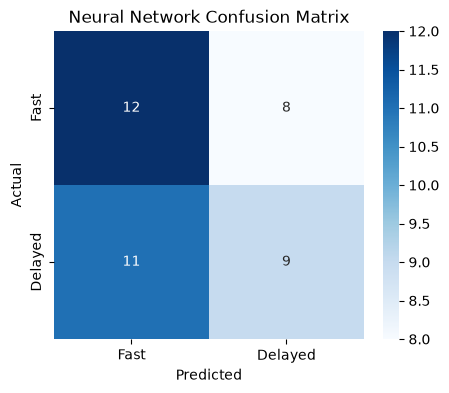

In [ ]:
cm_nn = confusion_matrix(
    y_test,
    y_pred_nn
)  # create neural network confusion matrix

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm_nn,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Fast', 'Delayed'],
    yticklabels=['Fast', 'Delayed']
)  # visualize the confusion matrix

plt.title('Neural Network Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# Neural Network Training Performance

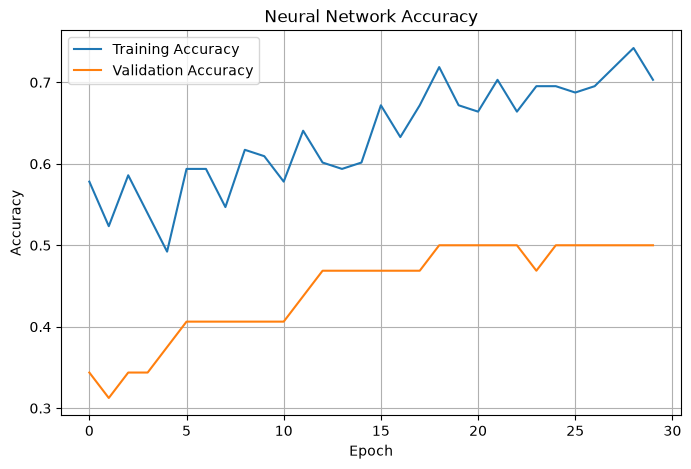

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history['accuracy'],
    label='Training Accuracy'
)  # plot training accuracy

plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)  # plot validation accuracy

plt.title('Neural Network Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

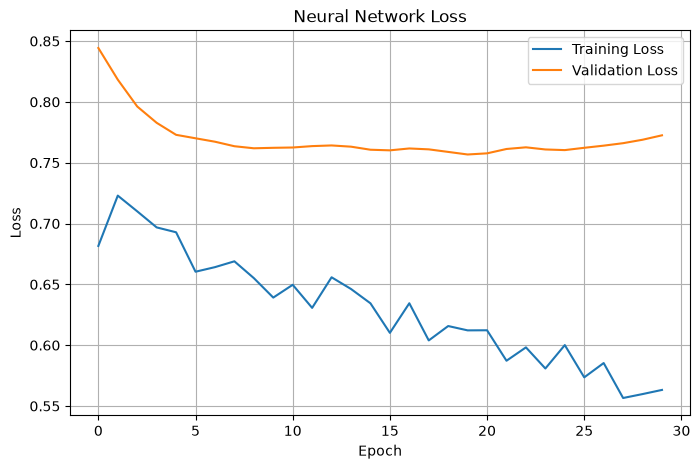

In [ ]:
# Loss
plt.figure(figsize=(8, 5))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)  # plot training loss

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)  # plot validation loss

plt.title('Neural Network Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

# Logistics Regression Baseline 

In [ ]:
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)  # create Logistic Regression model

In [ ]:
logistic_model.fit(
    X_train_scaled,
    y_train
)  # train Logistic Regression

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [ ]:
y_pred_logistic = logistic_model.predict(
    X_test_scaled
)  # predict delivery status

In [ ]:
# Evaluate 

logistic_accuracy = accuracy_score(
    y_test,
    y_pred_logistic
)  # calculate accuracy

logistic_precision = precision_score(
    y_test,
    y_pred_logistic
)  # calculate precision

logistic_recall = recall_score(
    y_test,
    y_pred_logistic
)  # calculate recall

logistic_f1 = f1_score(
    y_test,
    y_pred_logistic
)  # calculate F1-score

print("Accuracy :", round(logistic_accuracy, 4))
print("Precision:", round(logistic_precision, 4))
print("Recall   :", round(logistic_recall, 4))
print("F1-score :", round(logistic_f1, 4))

Accuracy : 0.475
Precision: 0.4762
Recall   : 0.5
F1-score : 0.4878


# Neural network vs Logistics regression

In [ ]:
model_comparison = pd.DataFrame({

    'Model': [
        'Logistic Regression',
        'Neural Network'
    ],

    'Accuracy': [
        logistic_accuracy,
        nn_accuracy
    ],

    'Precision': [
        logistic_precision,
        nn_precision
    ],

    'Recall': [
        logistic_recall,
        nn_recall
    ],

    'F1-Score': [
        logistic_f1,
        nn_f1
    ]

}).round(4)  # create model comparison table

model_comparison

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.475,0.4762,0.50,0.4878
1,Neural Network,0.525,0.5294,0.45,0.4865


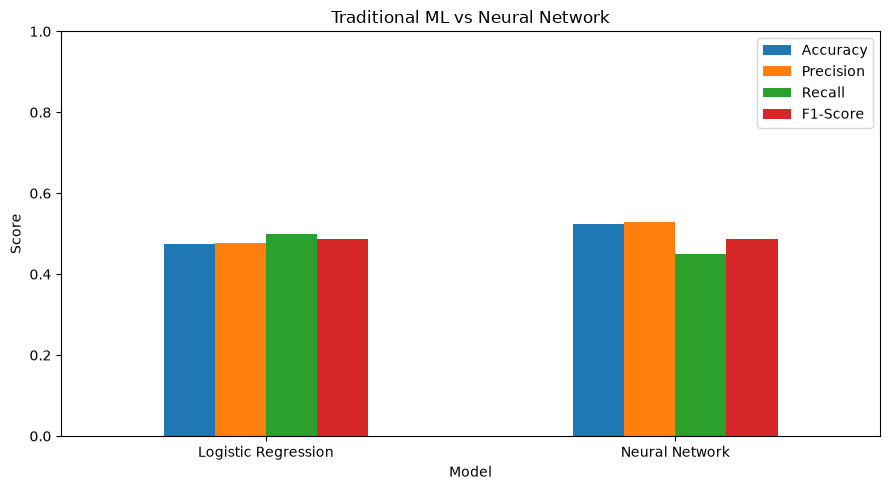

In [ ]:
model_comparison.set_index(
    'Model'
)[
    ['Accuracy', 'Precision', 'Recall', 'F1-Score']
].plot(
    kind='bar',
    figsize=(9, 5)
)  # compare model performance

plt.title('Traditional ML vs Neural Network')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Neural Network Hyperparameter Experiment 

In [ ]:
# Different Neurons 
def create_model(neurons=32, learning_rate=0.001):

    model = Sequential([
        
        Dense(
            neurons,
            activation='relu',
            input_shape=(X_train_scaled.shape[1],)
        ),  # first hidden layer

        Dense(
            neurons // 2,
            activation='relu'
        ),  # second hidden layer

        Dense(
            1,
            activation='sigmoid'
        )  # binary output layer
    ])

    optimizer = tf.keras.optimizers.Adam(
        learning_rate=learning_rate
    )  # create Adam optimizer with selected learning rate

    model.compile(
        optimizer=optimizer,
        loss='binary_crossentropy',
        metrics=['accuracy']
    )  # compile the model

    return model

In [ ]:
# Try Another Configuration:

model_tuned = create_model(
    neurons=64,
    learning_rate=0.0005
)  # create a larger network with a lower learning rate

/Users/shyamalkar/Desktop/ML_project/MLvenv/lib/python3.14/site-packages/keras/src/layers/core/dense.py:102: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
# Train 
history_tuned = model_tuned.fit(
    X_train_scaled,
    y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=16,
    callbacks=[early_stopping],
    verbose=0
)  # train the tuned neural network

In [ ]:
tuned_probability = model_tuned.predict(
    X_test_scaled,
    verbose=0
)  # predict delayed probability

y_pred_tuned = (
    tuned_probability >= 0.5
).astype(int).ravel()  # convert probability to class

print(
    "Tuned Accuracy:",
    round(
        accuracy_score(y_test, y_pred_tuned),
        4
    )
)

print(
    "Tuned Precision:",
    round(
        precision_score(y_test, y_pred_tuned),
        4
    )
)

print(
    "Tuned Recall:",
    round(
        recall_score(y_test, y_pred_tuned),
        4
    )
)

print(
    "Tuned F1:",
    round(
        f1_score(y_test, y_pred_tuned),
        4
    )
)

Tuned Accuracy: 0.475
Tuned Precision: 0.4737
Tuned Recall: 0.45
Tuned F1: 0.4615


In [ ]:
clustering_comparison = pd.DataFrame({

    'Method': [
        'K-Means',
        'Hierarchical'
    ],

    'Silhouette Score': [
        silhouette_k
        silhouette_hierarchical,
    ]

}).round(4)  # compare clustering quality

clustering_comparison

SyntaxError: invalid syntax. Perhaps you forgot a comma? (337397531.py, line 9)

# Cluster Delivery - TIme Analysis 

In [ ]:
cluster_delivery_analysis = df.groupby(
    'KMeans_Cluster'
)[
    [
        'Delivery_Time',
        'Haversine_Distance',
        'Order_Cost',
        'Tip_Amount'
    ]
].mean().round(2)  # compare delivery characteristics between clusters

cluster_delivery_analysis

,Delivery_Time,Haversine_Distance,Order_Cost,Tip_Amount
KMeans_Cluster,,,,
0,79.33,650.62,1446.68,36.60
1,66.84,593.37,772.55,54.51
2,66.75,570.07,1014.72,46.09


# Summary 

Food Delivery Time Prediction — Final Report
This project analyzed food delivery data using clustering and neural network techniques. The data was cleaned, categorical variables were encoded, geographical distance was calculated using the Haversine formula, and rush-hour information was engineered. K-Means clustering was used to identify groups of similar delivery patterns, while Hierarchical Clustering and dendrogram analysis provided an alternative view of the relationships between orders. A feedforward neural network was then developed to classify deliveries as Fast or Delayed and was compared with Logistic Regression. The clustering analysis can help identify high-risk delivery groups, while the neural network can support early prediction of delays. These insights can help businesses optimize routes, allocate delivery personnel, manage rush-hour demand, and improve overall delivery efficiency.